# Spatial Search on 2D Quantum Walk with Non-periodic Lattice


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from classiq import *

/Users/reisato/PycharmProjects/pythonProject1/.venv/lib/python3.11/site-packages/classiq/__init__.py:110: UserWarning: 'nest_asyncio2' is not installed; falling back to the legacy 'nest_asyncio'. 'nest_asyncio2' ships with modern Jupyter (ipykernel >= 7.3); consider upgrading your Jupyter installation, for example: pip install --upgrade jupyter ipykernel
  enable_jupyter_notebook()


In [3]:
d = 2
x_piece = 2**4
N = x_piece**d
k = 4
nx = int(np.ceil(np.log2(x_piece)))
nl = int(np.ceil(np.log2(k)))
NUM_SAMPLES = 1000
selected_times = [1, 10, 25, 35, 50]
print("N =", N, "nx =", nx, "nl =", nl)

N = 256 nx = 4 nl = 2


## Boundary labels for checking

These labels are only for visualization/debugging. The Qmod shift below does not keep a persistent label register; it checks the current position each walk step.


In [4]:
def compute_node_labels(x_piece):
    end = x_piece - 1
    labels = np.zeros((x_piece, x_piece), dtype=int)

    labels[0, :] = 1      # left edge  (x == 0)
    labels[end, :] = 2    # right edge (x == end)
    labels[:, 0] = 3      # bottom edge (y == 0)
    labels[:, end] = 4    # top edge    (y == end)

    labels[0, 0] = 5          # bottom-left corner
    labels[end, 0] = 6        # bottom-right corner
    labels[0, end] = 7        # top-left corner
    labels[end, end] = 8      # top-right corner
    return labels

node_labels = compute_node_labels(x_piece)
print(node_labels)

[[5 1 1 1 1 1 1 1 1 1 1 1 1 1 1 7]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
 [6 2 2 2 2 2 2 2 2 2 2 2 2 2 2 8]]


## Qmod implementation

Coin convention:

- `l == 0`: move to `x - 1`
- `l == 1`: move to `x + 1`
- `l == 2`: move to `y - 1`
- `l == 3`: move to `y + 1`

For non-periodic boundaries, outward directions are blocked. For blocked directions this implementation does **not** flip the coin; the amplitude stays in the same `(pos, l)` basis state. For allowed directions, it performs the usual flip-flop shift.


In [5]:
class pos_reg(QStruct):
    x: QNum[nx]
    y: QNum[nx]

In [6]:
@qfunc
def prepare_pos_state(pos: pos_reg):
    if x_piece == (2**nx):
        hadamard_transform(pos)
    else:
        prob_array = np.ones(2**nx) / x_piece
        prob_array[x_piece:2**nx] = 0
        inplace_prepare_state(prob_array.tolist(), 0.0, pos.x)
        inplace_prepare_state(prob_array.tolist(), 0.0, pos.y)


@qfunc
def prepare_coin_state(l: QNum[nl]):
    if k == 2**nl:
        hadamard_transform(l)
    elif k < 2**nl:
        prob_array = np.ones(2**nl) / k
        prob_array[k:2**nl] = 0
        inplace_prepare_state(prob_array.tolist(), 0.0, l)


@qfunc
def initial_state(pos: pos_reg, l: QNum):
    prepare_pos_state(pos)
    prepare_coin_state(l)

In [7]:
@qperm
def oracle_operator(pos: pos_reg):
    control(((pos.x == x_piece // 2) & (pos.y == x_piece // 2)), lambda: phase(np.pi))


@qfunc
def coin_operator(l: QNum):
    grover_diffuser(lambda psi: hadamard_transform(psi), l)

In [8]:
@qfunc
def shift_plus(p: QNum):
    p += 1


@qfunc
def shift_minus(p: QNum):
    p += -1


@qfunc
def mark_allowed_direction(pos: pos_reg, l: QNum, allowed: QBit):
    # The four cases are disjoint because they are conditioned on l.
    control((l == 0) & (pos.x > 0), lambda: X(allowed))
    control((l == 1) & (pos.x < x_piece - 1), lambda: X(allowed))
    control((l == 2) & (pos.y > 0), lambda: X(allowed))
    control((l == 3) & (pos.y < x_piece - 1), lambda: X(allowed))


@qfunc
def move_allowed_direction(pos: pos_reg, l: QNum, allowed: QBit):
    control(allowed, lambda: control(l == 0, lambda: shift_minus(pos.x)))
    control(allowed, lambda: control(l == 1, lambda: shift_plus(pos.x)))
    control(allowed, lambda: control(l == 2, lambda: shift_minus(pos.y)))
    control(allowed, lambda: control(l == 3, lambda: shift_plus(pos.y)))


@qfunc
def flip_operator(l: QArray):
    # l=0 <-> 1 and l=2 <-> 3 in this coin convention.
    X(l[0])


@qfunc
def shift_operator(pos: pos_reg, l: QNum, allowed: QBit):
    # allowed is true iff the current (position, coin) direction has an edge.
    # After an allowed flip-flop shift, the opposite direction is also allowed,
    # so the same predicate uncomputes allowed back to |0>.
    within_apply(
        within=lambda: mark_allowed_direction(pos, l, allowed),
        apply=lambda: [
            move_allowed_direction(pos, l, allowed),
            control(allowed, lambda: flip_operator(l)),
        ],
    )


@qfunc
def quantum_walk(pos: pos_reg, l: QNum, allowed: QBit):
    coin_operator(l)
    shift_operator(pos, l, allowed)


@qfunc
def coin_walk(t: CInt, pos: pos_reg, l: QNum, allowed: QBit):
    power(
        t,
        lambda: [oracle_operator(pos), quantum_walk(pos, l, allowed)],
    )

In [9]:
@qfunc
def main(t: CInt, p: Output[pos_reg]):
    l = QNum()
    allowed = QBit()
    allocate(p.size, p)
    allocate(nl, l)
    allocate(allowed)
    initial_state(p, l)
    coin_walk(t, p, l, allowed)
    drop(allowed)
    drop(l)

In [10]:
qprog = synthesize(main)
#show(qprog)

In [11]:
for t in selected_times:
    df = sample(qprog, backend="simulator", parameters={"t": t}, num_shots=NUM_SAMPLES)
    marked = df.loc[(df["p.x"] == x_piece // 2) & (df["p.y"] == x_piece // 2), "counts"]
    count = int(marked.iloc[0]) if len(marked) else 0
    print(f"t={t:3d}: counts={count:4d}, probability={count / NUM_SAMPLES:.4f}")

Submitting job to simulator
Job: https://platform.classiq.io/jobs/85df8dbd-61cd-4b00-81c1-83ee6c8af335
Submitting job to simulator


t=  1: counts=   4, probability=0.0040


Job: https://platform.classiq.io/jobs/26d5ec07-90e2-41fb-9a6a-704a620b7032
Submitting job to simulator


t= 10: counts=  82, probability=0.0820


Job: https://platform.classiq.io/jobs/69c792fc-bcc7-4a3e-90ed-32a6d34c9ba2
Submitting job to simulator


t= 25: counts= 208, probability=0.2080


Job: https://platform.classiq.io/jobs/3b7b5740-d952-4685-bb8b-e630cc7cdc01
Submitting job to simulator


t= 35: counts= 139, probability=0.1390


Job: https://platform.classiq.io/jobs/1ff6ebe1-7ea4-4776-8520-1bc2a09e2366


t= 50: counts=   0, probability=0.0000


## Direct statevector reference


max probability = 0.269195 at t = 75
{1: 0.00390625, 10: 0.09164810180664062, 25: 0.22422619344028227, 35: 0.13516466147157066, 50: 0.0009985259566416013}


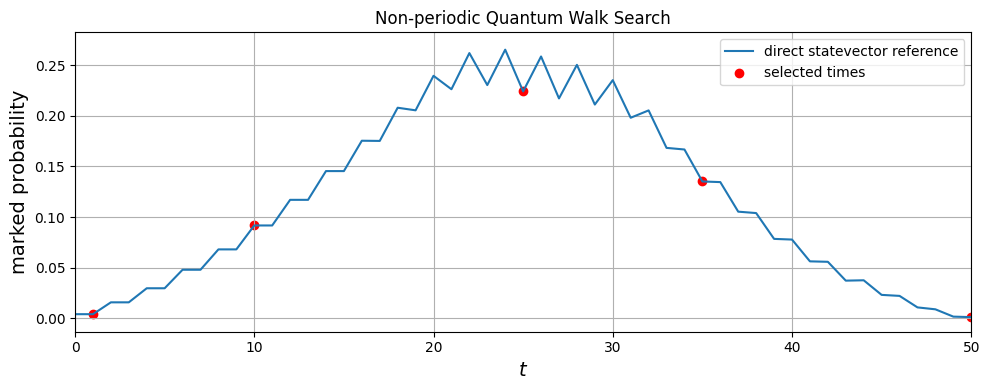

In [14]:
def simulate_nonperiodic_reference(x_piece, itr):
    C = np.array([[-1, 1, 1, 1],
                  [ 1,-1, 1, 1],
                  [ 1, 1,-1, 1],
                  [ 1, 1, 1,-1]]) / 2

    marked_x = x_piece // 2
    marked_y = x_piece // 2
    psi = np.ones((x_piece, x_piece, 4), dtype=complex) / np.sqrt(x_piece * x_piece * 4)
    probs = []

    for t in range(itr):
        if t != 0:
            psi[marked_x, marked_y] *= -1
            psi = np.einsum("ab,xyb->xya", C, psi)
            next_psi = np.zeros_like(psi)

            for x in range(x_piece):
                for y in range(x_piece):
                    # l=0: x- direction. Allowed only if x > 0.
                    if x > 0:
                        next_psi[x - 1, y, 1] += psi[x, y, 0]
                    else:
                        next_psi[x, y, 0] += psi[x, y, 0]

                    # l=1: x+ direction. Allowed only if x < end.
                    if x < x_piece - 1:
                        next_psi[x + 1, y, 0] += psi[x, y, 1]
                    else:
                        next_psi[x, y, 1] += psi[x, y, 1]

                    # l=2: y- direction. Allowed only if y > 0.
                    if y > 0:
                        next_psi[x, y - 1, 3] += psi[x, y, 2]
                    else:
                        next_psi[x, y, 2] += psi[x, y, 2]

                    # l=3: y+ direction. Allowed only if y < end.
                    if y < x_piece - 1:
                        next_psi[x, y + 1, 2] += psi[x, y, 3]
                    else:
                        next_psi[x, y, 3] += psi[x, y, 3]

            psi = next_psi

        probs.append(float(np.sum(np.abs(psi[marked_x, marked_y]) ** 2)))

    return np.array(probs)

itr = 170
time_list = np.arange(itr)
reference_prob = simulate_nonperiodic_reference(x_piece, itr)
print(f"max probability = {reference_prob.max():.6f} at t = {reference_prob.argmax()}")
print({t: float(reference_prob[t]) for t in selected_times})

plt.figure(figsize=(10, 4))
plt.plot(time_list, reference_prob, label="direct statevector reference")
plt.scatter(selected_times, [float(reference_prob[t]) for t in selected_times], color="red", label="selected times")
plt.xlabel(r"$t$", fontsize=14)
plt.ylabel("marked probability", fontsize=14)
plt.title("Non-periodic Quantum Walk Search")
plt.grid(True)
plt.xlim(0, 50)
plt.legend()
plt.tight_layout()
plt.show()